# Лабораторная работа 2

Датасет: MonoHime/ru_sentiment_dataset

Классы: нейтральный, положительный и отрицательный.

In [6]:
import re, json, random
from collections import Counter

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from datasets import load_dataset
from navec import Navec
from gensim.models import KeyedVectors
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.manifold import TSNE
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords', quiet=True)
stop = set(nltk.corpus.stopwords.words('russian'))
np.random.seed(42)
torch.manual_seed(42)
labels_names = {0: 'нейтральный', 1: 'положительный', 2: 'отрицательный'}
device = torch.device('mps')

## 1. TF-IDF и логистическая регрессия

In [7]:
ds = load_dataset('MonoHime/ru_sentiment_dataset', split='train')
df = ds.to_pandas()[['text', 'sentiment']].dropna().drop_duplicates('text')

# одинаковое число текстов каждого класса
df = pd.concat([x.sample(2500, random_state=42) for _, x in df.groupby('sentiment')])
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df['sentiment'].value_counts().sort_index()

sentiment
0    2500
1    2500
2    2500
Name: count, dtype: int64

In [9]:
def clean(text):
    words = re.findall(r'[а-яё]+', text.lower())
    return ' '.join(w for w in words if w not in stop and len(w) > 1)

df['clean'] = df['text'].map(clean)
for i in range(3):
    print('ДО:   ', df.loc[i, 'text'][:250])
    print('ПОСЛЕ:', df.loc[i, 'clean'][:250], '\n')

ДО:    Это очень классный отель. Было бы чудесно, если бы коврики в коридорах были бы лучше почищены. Ну и в целом опрятность страдает. А в целом можно жить и радоваться своим каникулам в Стамбуле. Цена тоже приемлемая!
ПОСЛЕ: это очень классный отель чудесно коврики коридорах почищены целом опрятность страдает целом жить радоваться своим каникулам стамбуле цена приемлемая 

ДО:    Ужас Всем добрый день! Хотела написать всем желающим сделать что-либо у этого хирурга, - девочки, не тратьте свое время и деньги на этого безбожного хирурга. Опыта никакого, но море амбиций. Вытянул из меня сотни долларов под предлогом, что нужно (об
ПОСЛЕ: ужас всем добрый день хотела написать всем желающим сделать либо хирурга девочки тратьте свое время деньги безбожного хирурга опыта никакого море амбиций вытянул сотни долларов предлогом нужно обязательно нужно исправить это это это сделаю огромную с 

ДО:    Все чудесно , но не смотря , что найти ресторан непросто там очень много людей , очень много .  И

In [11]:
train_df, test_df = train_test_split(df, test_size=.2, random_state=42, stratify=df['sentiment'])
tfidf = TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 2))
X_train = tfidf.fit_transform(train_df['clean'])
X_test = tfidf.transform(test_df['clean'])

lr = LogisticRegression(max_iter=500, C=3)
lr.fit(X_train, train_df['sentiment'])
pred = lr.predict(X_test)

TF показывает частоту слова внутри текста. IDF уменьшает вес слов, которые встречаются почти во всех текстах

Вместе они выделяют слова, характерные именно для данного документа.

In [14]:
names = np.array(tfidf.get_feature_names_out())
for row, cls in enumerate(lr.classes_):
    best = np.argsort(lr.coef_[row])[-12:][::-1]
    print(labels_names[int(cls)], ':', ', '.join(names[best]))

нейтральный : вполне, достаточно, целом, минут, неплохой, завтрак, метро, интерьер, неплохо, близко, пару, вроде
положительный : благодарность, спасибо, отличный, очень, довольна, удовольствием, рекомендую, внимательный, поблагодарить, помогли, города, проблем
отрицательный : врач, отношение, свадьбу, обслуживание, музыка, деньги, ресторане, ресторана, день, никому, ужас, вкусная


accuracy=0.7180 precision=0.7240 recall=0.7180 f1=0.7166


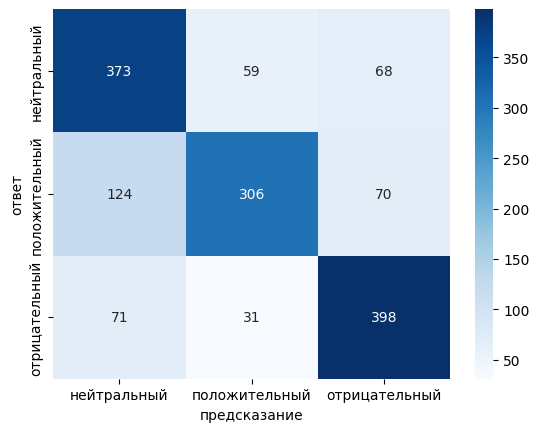

In [16]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average='weighted')
    return accuracy_score(y, p), pr, rc, f1

acc_tfidf, pr, rc, f1 = metrics(test_df['sentiment'], pred)
print(f'accuracy={acc_tfidf:.4f} precision={pr:.4f} recall={rc:.4f} f1={f1:.4f}')

cm = confusion_matrix(test_df['sentiment'], pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_names.values(), yticklabels=labels_names.values())
plt.xlabel('предсказание'); plt.ylabel('ответ'); plt.show()

In [17]:
errors = test_df[['text', 'sentiment']].copy()
errors['pred'] = pred
errors = errors[errors['sentiment'] != errors['pred']].head(5)
for _, row in errors.iterrows():
    print('Текст:', row.text[:350])
    print('Ответ:', labels_names[row.sentiment], '| модель:', labels_names[row.pred], '\n')

Текст: Ладно, хорошо, аборт это плохо, но тогда нужно вовсе Недпускать рождения детей в некорректных условиях. 
Ответ: нейтральный | модель: отрицательный 

Текст: В Стамбуле проходила выставка кожаных изделий производства Турция. Отель находится не далеко от аэропорта и непосредственно в бизнес районе , где расположены фабрики и шоурумы кожи.Отель с завтраками . Хорошие завтраки . Понравилась очень девушка на рецепции . Грамотная, доброжелательная и со знанием русского языка. Заметно , что в отеле недавно бы
Ответ: нейтральный | модель: положительный 

Текст: Даже не ожидала , что в нашем районе есть такой замечательный ресторан !  Приятная атмосфера , замечательный персонал ( большое спасибо Гуле ) , вкусная еда ( цена - качество даже не обсуждается ! ) .  Обязательно зайду сюда еще !!!  
Ответ: отрицательный | модель: положительный 

Текст: место приятное . друзья , с которыми я была , в один голос восхищались уютом этого ресторанчика . меня порадовало разнообразие чаев - и дедушкин

Ошибки чаще встречаются в коротких и неоднозначных сообщениях. Ещё модель не понимает иронию и отрицание в целом, веса идут к конкретным словам

Отдельно встречаются проблемы с датасетом, у него бывают шумные разметки, например пример 3 хоть и ошибочен по разметке, но по сути правильный

## 2. Статические эмбеддинги

Готового русского GloVe в `gensim.downloader` нет, поэтому использован Navec — статические векторы, обученные на русской художественной литературе. Принцип тот же, у каждого слова один постоянный вектор.

In [18]:
navec = Navec.load('data/navec_hudlit_v1_12B_500K_300d_100q.tar')

# Для операций most_similar берём часть словаря и добавляем слова из экспериментов.
required = ['кошка','город','врач','радость','море','король','мужчина','женщина',
            'собака','лошадь','волк','лиса','медведь','тигр','заяц','россия',
            'германия','франция','италия','китай','япония','индия','испания',
            'учитель','инженер','водитель','писатель','актёр','повар','юрист',
            'грусть','страх','злость','восторг','тоска','стыд','удивление']
words60 = list(dict.fromkeys(list(navec.vocab.words[:60000]) + required))
kv = KeyedVectors(vector_size=300)
kv.add_vectors(words60, np.array([navec[w] for w in words60]))
print('слов в рабочем словаре:', len(kv))

слов в рабочем словаре: 60036


In [19]:
for word in ['кошка', 'город', 'врач', 'радость', 'море']:
    print(word, '->', [(w, round(s, 3)) for w, s in kv.most_similar(word, topn=5)])

print('\nкороль - мужчина + женщина:')
print(kv.most_similar(positive=['король', 'женщина'], negative=['мужчина'], topn=5))

кошка -> [('собака', 0.671), ('лиса', 0.528), ('волк', 0.477), ('бездомная', 0.459), ('ведьма', 0.45)]
город -> [('багдад', 0.508), ('весь', 0.446), ('аэропорт', 0.445), ('амстердам', 0.421), ('берлин', 0.418)]
врач -> [('ветеринар', 0.598), ('больной', 0.572), ('больнице', 0.56), ('больного', 0.509), ('больницу', 0.484)]
радость -> [('грусть', 0.571), ('восторг', 0.565), ('блаженство', 0.549), ('благодарность', 0.493), ('боль', 0.472)]
море -> [('берег', 0.603), ('берега', 0.581), ('берегу', 0.561), ('берегов', 0.56), ('бухты', 0.483)]

король - мужчина + женщина:
[('величество', 0.556874692440033), ('баронесса', 0.46988463401794434), ('австрийская', 0.4316774904727936), ('анна', 0.41898414492607117), ('англия', 0.4184730648994446)]


Векторная арифметика пытается сохранить отношение между понятиями, от мужского перешла к нейтральным и женским вариантам. Результат приблизительный, одинаковые по смыслу слова иногда мешают явно определить, например слово "веичество", но всё равно достойный результат, по крайней мере на этих примерах

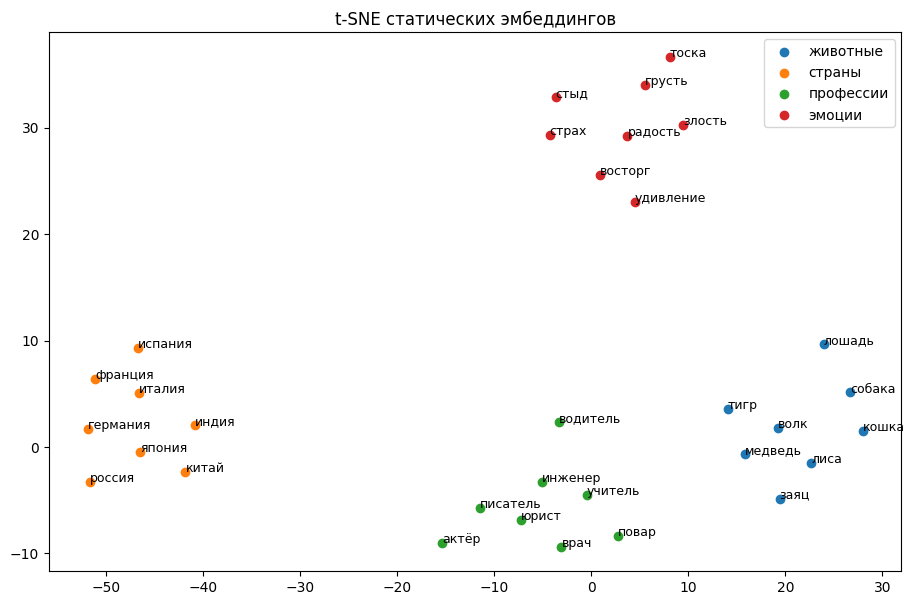

In [22]:
groups = {
    'животные': ['кошка','собака','лошадь','волк','лиса','медведь','тигр','заяц'],
    'страны': ['россия','германия','франция','италия','китай','япония','индия','испания'],
    'профессии': ['врач','учитель','инженер','водитель','писатель','актёр','повар','юрист'],
    'эмоции': ['радость','грусть','страх','злость','восторг','тоска','стыд','удивление']
}
plot_words, colors, vecs = [], [], []
for group, ws in groups.items():
    for w in ws:
        plot_words.append(w); colors.append(group); vecs.append(kv[w])

points = TSNE(n_components=2, perplexity=8, init='pca', learning_rate='auto',
              random_state=42).fit_transform(np.array(vecs))
plt.figure(figsize=(11, 7))
for group in groups:
    ids = [i for i, x in enumerate(colors) if x == group]
    plt.scatter(points[ids,0], points[ids,1], label=group)
for i, w in enumerate(plot_words):
    plt.annotate(w, points[i], fontsize=9)
plt.legend(); plt.title('t-SNE статических эмбеддингов'); plt.show()

Все слова в этом примере объединились в чёткие кластеры, хотя t-SNE сохраняет локальное соседство, а у слов могут быть дополнительные значения

Такие хорошие кластеры могут быть объяснены простейшими и короткими примерами. Длинные текста будут гораздо хуже

In [23]:
def mean_vec(text):
    ws = [w for w in text.split() if w in kv]
    return np.mean([kv[w] for w in ws], axis=0) if ws else np.zeros(300)

Xtr_emb = np.array([mean_vec(x) for x in train_df['clean']])
Xte_emb = np.array([mean_vec(x) for x in test_df['clean']])
lr_emb = LogisticRegression(max_iter=500)
lr_emb.fit(Xtr_emb, train_df['sentiment'])
pred_emb = lr_emb.predict(Xte_emb)
acc_emb = accuracy_score(test_df['sentiment'], pred_emb)
print('accuracy усреднённых Navec:', round(acc_emb, 4))

accuracy усреднённых Navec: 0.546


## 3. Нейронная сеть

In [25]:
all_words = Counter(' '.join(train_df['clean']).split())
vocab = {'<PAD>': 0, '<UNK>': 1}
for w, _ in all_words.most_common(19998):
    vocab[w] = len(vocab)

def encode(text, max_len=120):
    ids = [vocab.get(w, 1) for w in text.split()[:max_len]]
    return ids + [0] * (max_len - len(ids))

xtr = torch.tensor([encode(x) for x in train_df['clean']], dtype=torch.long)
xte = torch.tensor([encode(x) for x in test_df['clean']], dtype=torch.long)
ytr = torch.tensor(train_df['sentiment'].to_numpy(), dtype=torch.long)
yte = torch.tensor(test_df['sentiment'].to_numpy(), dtype=torch.long)

tr_loader = DataLoader(TensorDataset(xtr, ytr), batch_size=128, shuffle=True)
te_loader = DataLoader(TensorDataset(xte, yte), batch_size=256)

In [29]:
from torch.utils.data import random_split

full_train = tr_loader.dataset

val_size = int(len(full_train) * 0.2)
train_size = len(full_train) - val_size

train_data, val_data = random_split(full_train, [train_size, val_size], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
val_loader = DataLoader(val_data, batch_size=256)


class TextNet(nn.Module):
    def __init__(self, weights=None, frozen=False):
        super().__init__()

        self.embedding = nn.Embedding(len(vocab), 300, padding_idx=0)

        if weights is not None:
            self.embedding.weight.data.copy_(torch.tensor(weights))

        if frozen:
            self.embedding.weight.requires_grad = False

        self.linear1 = nn.Linear(300, 128)
        self.linear2 = nn.Linear(128, 3)

    def forward(self, x):
        vectors = self.embedding(x)

        mask = (x != 0).unsqueeze(2)
        vectors = vectors * mask

        average = vectors.sum(dim=1)
        average = average / mask.sum(dim=1).clamp(min=1)

        hidden = torch.relu(self.linear1(average))
        return self.linear2(hidden)


def train_model(model, epochs=10):
    model = model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()

    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            predictions = model(x)
            loss = loss_function(predictions, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(y)
            correct += (predictions.argmax(1) == y).sum().item()
            total += len(y)

        train_losses.append(total_loss / total)
        train_accuracies.append(correct / total)

        model.eval()

        total_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(device)
                y = y.to(device)

                predictions = model(x)
                loss = loss_function(predictions, y)

                total_loss += loss.item() * len(y)
                correct += (predictions.argmax(1) == y).sum().item()
                total += len(y)

        val_losses.append(total_loss / total)
        val_accuracies.append(correct / total)

        print(
            epoch + 1,
            round(train_losses[-1], 4),
            round(train_accuracies[-1], 4),
            round(val_losses[-1], 4),
            round(val_accuracies[-1], 4)
        )

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in te_loader:
            x = x.to(device)
            y = y.to(device)

            predictions = model(x)

            correct += (predictions.argmax(1) == y).sum().item()
            total += len(y)

    test_accuracy = correct / total

    return (
        model,
        train_losses,
        train_accuracies,
        val_losses,
        val_accuracies,
        test_accuracy
    )

In [30]:
random_model, loss_random, train_acc_random, val_loss_random, val_acc_random, acc_random = train_model(TextNet())

print('test accuracy:', round(acc_random, 4))

1 1.0499 0.489 0.9885 0.5308
2 0.8884 0.6162 0.8726 0.5958
3 0.725 0.6887 0.8273 0.6225
4 0.5894 0.7592 0.8261 0.6442
5 0.4773 0.8175 0.8485 0.6458
6 0.3747 0.864 0.9004 0.6317
7 0.2836 0.9102 0.9319 0.6425
8 0.2053 0.9425 0.9989 0.6517
9 0.1432 0.9683 1.0913 0.6325
10 0.1012 0.98 1.1504 0.6467
test accuracy: 0.6447


In [31]:
weights = np.random.normal(0, .05, (len(vocab), 300)).astype('float32')
weights[0] = 0
found = 0
for w, i in vocab.items():
    if w in navec:
        weights[i] = navec[w]; found += 1
print('найдено слов в Navec:', found)

pre_model, loss_pre, train_acc_pre, val_loss_pre, val_acc_pre, acc_pre = train_model(TextNet(weights, frozen=True))

print('test accuracy:', round(acc_pre, 4))

найдено слов в Navec: 19404
1 1.0158 0.5629 0.9161 0.6008
2 0.8447 0.6231 0.7995 0.6467
3 0.7653 0.6592 0.758 0.6592
4 0.7225 0.6794 0.7378 0.6725
5 0.6927 0.6981 0.7203 0.6708
6 0.6712 0.7058 0.7079 0.6767
7 0.6524 0.7135 0.6968 0.6825
8 0.6364 0.7225 0.7029 0.6917
9 0.6244 0.7258 0.6903 0.6917
10 0.61 0.7385 0.6882 0.69
test accuracy: 0.7033


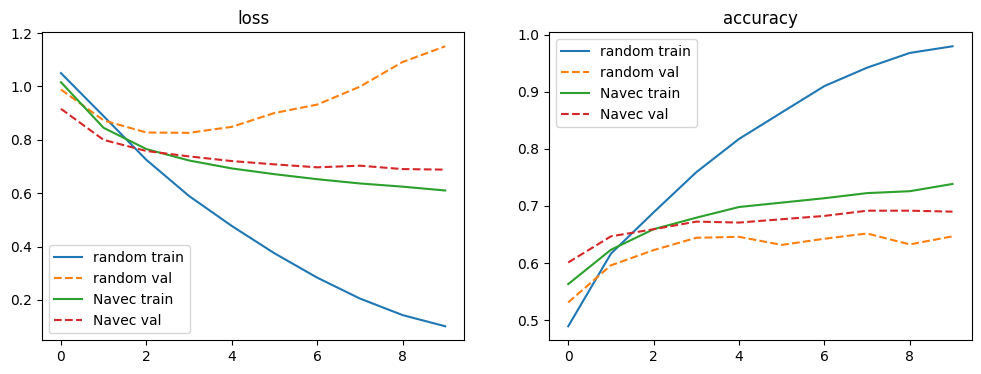

,Метод,Test Accuracy
0,Логистическая регрессия (TF-IDF),0.718000
1,Логистическая регрессия (средние Navec),0.546000
2,Нейросеть (Random Embedding),0.644667
3,"Нейросеть (Navec, заморожен)",0.703333


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(loss_random, label='random train'); ax[0].plot(val_loss_random, '--', label='random val')
ax[0].plot(loss_pre, label='Navec train'); ax[0].plot(val_loss_pre, '--', label='Navec val')
ax[0].set_title('loss'); ax[0].legend()
ax[1].plot(train_acc_random, label='random train'); ax[1].plot(val_acc_random, '--', label='random val')
ax[1].plot(train_acc_pre, label='Navec train'); ax[1].plot(val_acc_pre, '--', label='Navec val')
ax[1].set_title('accuracy'); ax[1].legend()
plt.show()

results = {
    'Логистическая регрессия (TF-IDF)': acc_tfidf,
    'Логистическая регрессия (средние Navec)': acc_emb,
    'Нейросеть (Random Embedding)': acc_random,
    'Нейросеть (Navec, заморожен)': acc_pre
}
display(pd.DataFrame(results.items(), columns=['Метод', 'Test Accuracy']))

Модель со случайными эмбеддингами быстро переобучилась. У модели с Navec разница между train и validation заметно меньше, она показала более стабильный результат

Лучшей оказалась логистическая регрессия с TF-IDF. Нейросеть с замороженными Navec дала близкий результат. Простое усреднение Navec с логистической регрессией сработало хуже всего, потому что при усреднении теряется часть информации о тексте